# OLS Realized Variance Forecasts

Two models predict next month's log realized variance for XLI, XLB, XLE, XLY, and XLF. `ols_1m` uses the current month's log variance; `ols_1_3_12m` adds trailing 3- and 12-month averages of monthly log variance. Each model uses its own complete sample, a 60-month burn-in, and monthly expanding-window refits. The 1-month model aligns with Elastic Net's forecast dates; the 1/3/12-month model starts later because of its longer predictors. January 2003 is excluded upstream.

`date` is the predictor month and `target_date` is the next month. Level forecasts use the Phase 2 out-of-fold log-normal correction. Only forecasts are exported; accuracy and coefficients are displayed below.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import TimeSeriesSplit


PROJECT_ROOT = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "dataset/price/clean/realized_variance.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from within the project directory.")
BURN_IN = 60
from IPython.display import display
TICKERS = ["XLI", "XLB", "XLE", "XLY", "XLF"]
FEATURE_SETS = {
    "ols_1m": ["log_rv_1m"],
    "ols_1_3_12m": ["log_rv_1m", "log_rv_avg_3m", "log_rv_avg_12m"],
}

In [2]:
def fit_forecasts(panel, burn_in=60):
    """Fit each ETF separately, using only earlier rows for each forecast."""
    if burn_in < 6:
        raise ValueError("burn_in must be at least 6 for five time-series CV splits.")
    panel = panel.copy()
    panel["date"] = pd.to_datetime(panel["date"], errors="raise")
    if panel["date"].isna().any() or panel.duplicated(["date", "etf"]).any():
        raise ValueError("Dates must be valid and ETF-month rows must be unique.")
    rows, coefficients = [], []
    for ticker in TICKERS:
        data = panel.loc[panel["etf"].eq(ticker)].sort_values("date").copy()
        if data.empty:
            raise ValueError(f"No observations for {ticker}.")
        periods = pd.PeriodIndex(data["date"], freq="M")
        if not np.all(np.diff(periods.asi8) == 1):
            raise ValueError(f"{ticker} must have consecutive monthly observations.")
        data["target"] = data["log_rv_1m"].shift(-1)
        data["target_date"] = data["date"].shift(-1)
        for name, features in FEATURE_SETS.items():
            model_data = data.dropna(subset=features + ["target"]).reset_index(drop=True)
            if len(model_data) <= burn_in:
                raise ValueError(f"Insufficient complete history for {ticker}, {name}.")
            if not np.isfinite(model_data[features + ["target"]].to_numpy()).all():
                raise ValueError(f"Non-finite log variances for {ticker}, {name}.")
            y = model_data["target"].to_numpy()
            x = model_data[features].to_numpy()
            for i in range(burn_in, len(model_data)):
                x_train, y_train = x[:i], y[:i]
                model = LinearRegression().fit(x_train, y_train)
                oof = np.full(i, np.nan)
                for train, test in TimeSeriesSplit(n_splits=5).split(x_train):
                    fold = LinearRegression().fit(x_train[train], y_train[train])
                    oof[test] = fold.predict(x_train[test])
                tested = np.isfinite(oof)
                sigma2 = float(np.var(y_train[tested] - oof[tested]))
                pred = float(model.predict(x[i:i + 1])[0])
                rows.append({
                    "model": name, "etf": ticker,
                    "date": model_data.loc[i, "date"],
                    "target_date": model_data.loc[i, "target_date"],
                    "actual_logRV": y[i], "actual_RV": np.exp(y[i]),
                    "fc_log": pred, "sigma2": sigma2,
                    "fc_level": np.exp(pred + 0.5 * sigma2),
                    "train_months": i,
                })
                coefficients.append({
                    "model": name, "etf": ticker, "date": model_data.loc[i, "date"],
                    "intercept": model.intercept_,
                    **dict(zip(features, model.coef_)),
                })
    return pd.DataFrame(rows), pd.DataFrame(coefficients)

In [3]:
panel = pd.read_csv(PROJECT_ROOT / "dataset/price/clean/realized_variance.csv")
forecasts, coefficients = fit_forecasts(panel, BURN_IN)
print(f"{len(forecasts):,} forecasts across two models and five ETFs")
display(forecasts.head(10))

2,085 forecasts across two models and five ETFs


,model,etf,date,target_date,actual_logRV,actual_RV,fc_log,sigma2,fc_level,train_months
0,ols_1m,XLI,2008-02-29,2008-03-31,-4.808556,0.008160,-6.073816,0.296840,0.002671,60
1,ols_1m,XLI,2008-03-31,2008-04-30,-5.344238,0.004776,-5.407213,0.328962,0.005286,61
2,ols_1m,XLI,2008-04-30,2008-05-31,-6.324658,0.001792,-5.749477,0.305806,0.003711,62
3,ols_1m,XLI,2008-05-31,2008-06-30,-5.424881,0.004406,-6.404696,0.258955,0.001882,63
4,ols_1m,XLI,2008-06-30,2008-07-31,-4.750961,0.008643,-5.815395,0.272630,0.003417,64
5,ols_1m,XLI,2008-07-31,2008-08-31,-5.250659,0.005244,-5.300956,0.301215,0.005797,65
6,ols_1m,XLI,2008-08-31,2008-09-30,-4.664348,0.009425,-5.634712,0.337327,0.004228,66
7,ols_1m,XLI,2008-09-30,2008-10-31,-2.912760,0.054326,-5.159648,0.334859,0.006791,67
8,ols_1m,XLI,2008-10-31,2008-11-30,-3.729418,0.024007,-3.495005,0.416389,0.037373,68
9,ols_1m,XLI,2008-11-30,2008-12-31,-3.924680,0.019748,-4.214097,0.421111,0.018251,69


## Accuracy

In [4]:
scores = forecasts.assign(
    squared_error=(forecasts["actual_logRV"] - forecasts["fc_log"]) ** 2,
    absolute_error=(forecasts["actual_logRV"] - forecasts["fc_log"]).abs(),
    qlike=forecasts["actual_RV"] / forecasts["fc_level"]
    - np.log(forecasts["actual_RV"] / forecasts["fc_level"]) - 1,
).groupby(["model", "etf"]).agg(
    n_forecasts=("fc_log", "size"),
    MSE_logRV=("squared_error", "mean"),
    MAE_logRV=("absolute_error", "mean"),
    QLIKE=("qlike", "mean"),
).reset_index()

display(scores)

,model,etf,n_forecasts,MSE_logRV,MAE_logRV,QLIKE
0,ols_1_3_12m,XLB,203,0.437586,0.499123,0.425592
1,ols_1_3_12m,XLE,203,0.425587,0.481520,0.301908
2,ols_1_3_12m,XLF,203,0.626277,0.597232,0.572782
3,ols_1_3_12m,XLI,203,0.499240,0.539870,0.343791
4,ols_1_3_12m,XLY,203,0.512243,0.557879,0.318520
5,ols_1m,XLB,214,0.462137,0.512037,0.296119
6,ols_1m,XLE,214,0.452351,0.498689,0.296287
7,ols_1m,XLF,214,0.665577,0.626864,0.404380
8,ols_1m,XLI,214,0.529249,0.556531,0.338877
9,ols_1m,XLY,214,0.505010,0.561203,0.297402


## Accuracy Charts

Grouped bars show the accuracy results above. The models have different evaluation periods (214 versus 203 forecasts per ETF); these are full-sample results, not a comparison over identical months. Lower values are better for all three metrics.

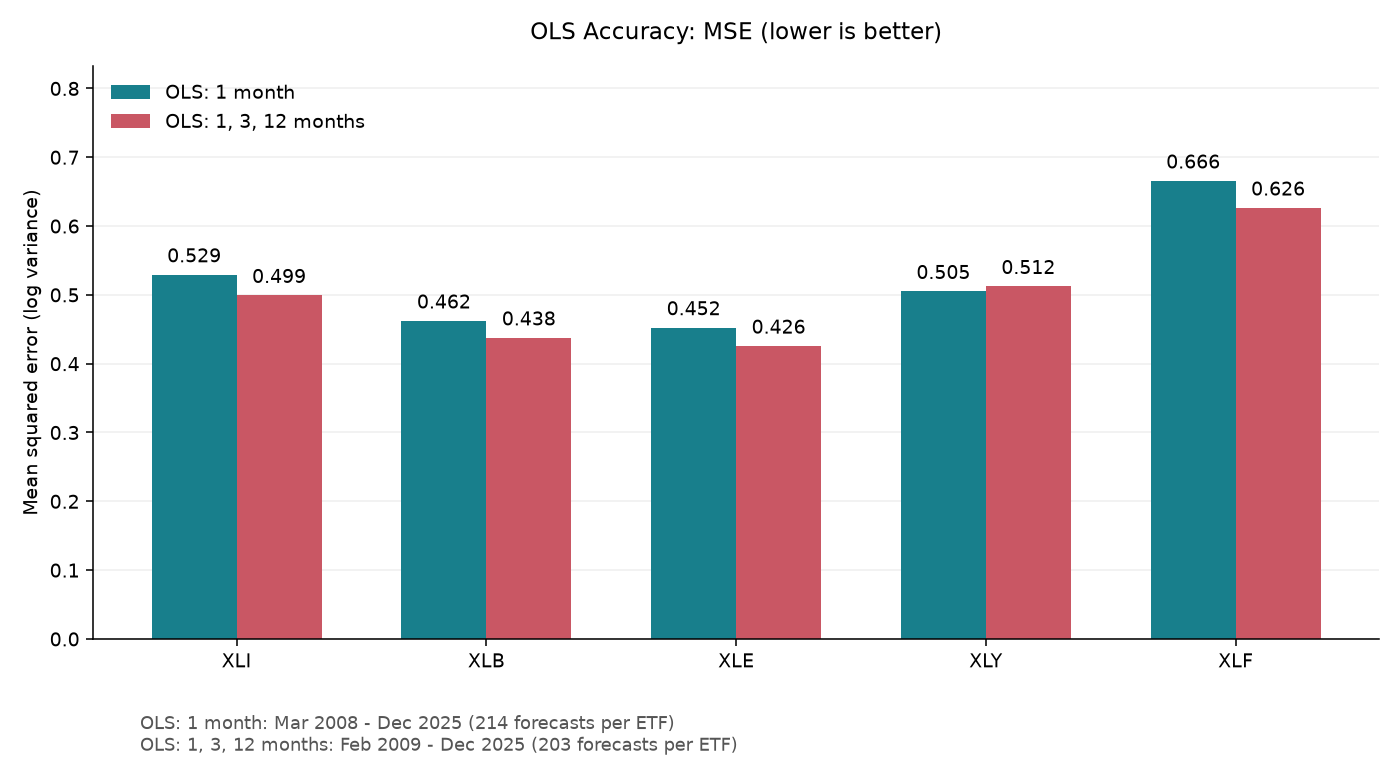

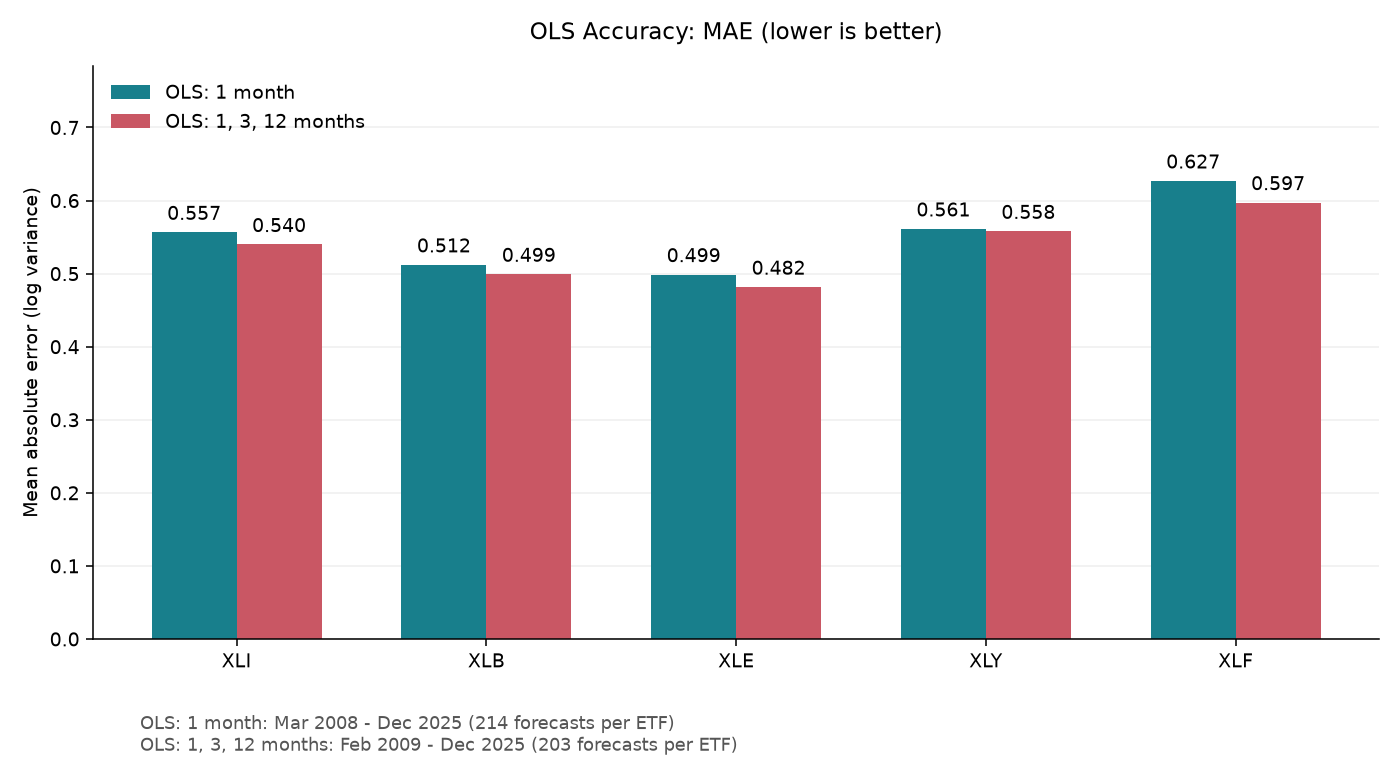

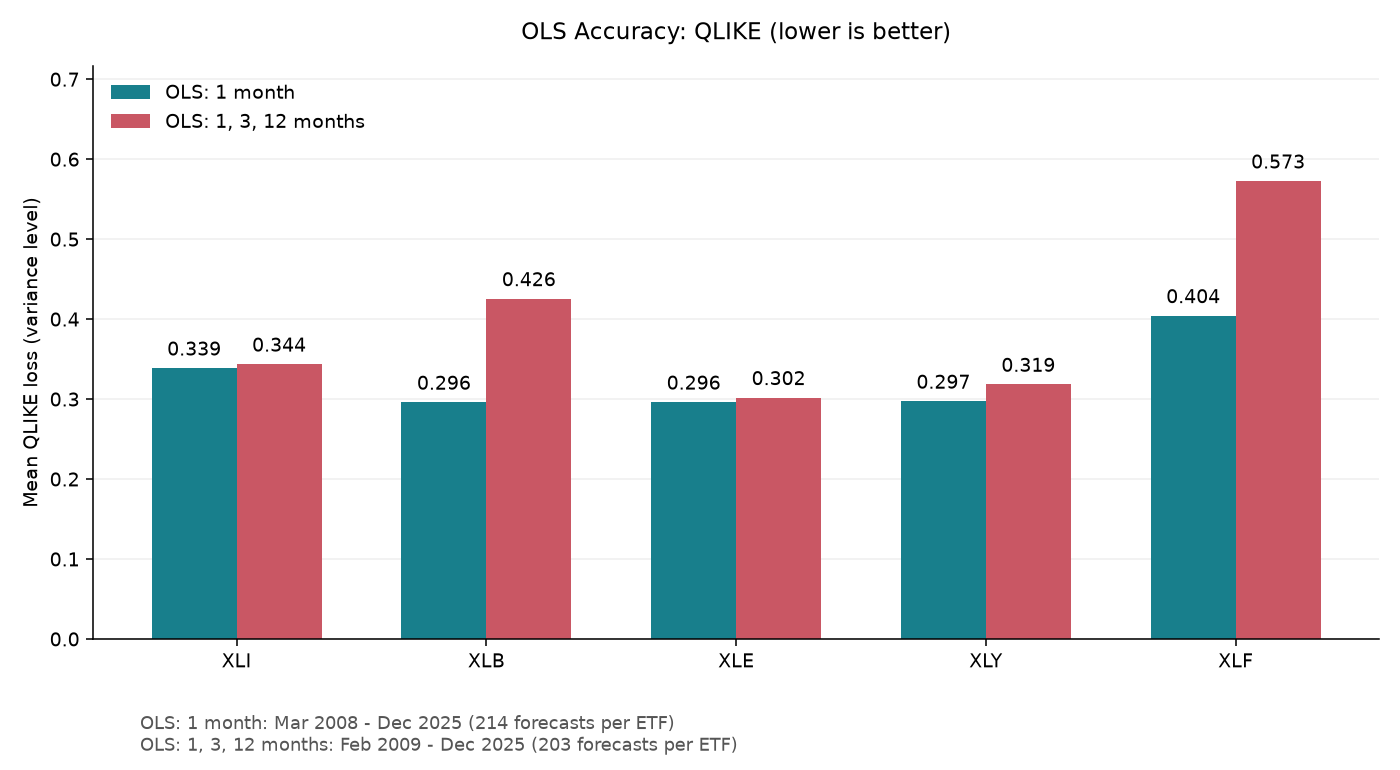

In [5]:
import matplotlib.pyplot as plt

model_labels = {"ols_1m": "OLS: 1 month", "ols_1_3_12m": "OLS: 1, 3, 12 months"}
model_colors = {"ols_1m": "#187f8c", "ols_1_3_12m": "#c95764"}
period_labels = []
for name in FEATURE_SETS:
    sample = forecasts.loc[forecasts["model"].eq(name)]
    dates = pd.to_datetime(sample["target_date"])
    counts = sample.groupby("etf").size()
    period_labels.append(
        f"{model_labels[name]}: {dates.min():%b %Y} - {dates.max():%b %Y} "
        f"({counts.min()} forecasts per ETF)"
    )

accuracy_figures = {}
for metric, title, ylabel in [
    ("MSE_logRV", "MSE", "Mean squared error (log variance)"),
    ("MAE_logRV", "MAE", "Mean absolute error (log variance)"),
    ("QLIKE", "QLIKE", "Mean QLIKE loss (variance level)"),
]:
    values = scores.pivot(index="etf", columns="model", values=metric).reindex(TICKERS)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    positions = np.arange(len(TICKERS))
    width = 0.34
    for j, name in enumerate(FEATURE_SETS):
        bars = ax.bar(
            positions + (j - 0.5) * width, values[name], width,
            label=model_labels[name], color=model_colors[name],
        )
        ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=10)
    ax.set_xticks(positions, TICKERS)
    ax.set_ylabel(ylabel)
    ax.set_title(f"OLS Accuracy: {title} (lower is better)", pad=14)
    ax.set_ylim(0, values.max().max() * 1.25)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, loc="upper left")
    fig.text(0.1, 0.025, "\n".join(period_labels), fontsize=9, color="#555555")
    fig.tight_layout(rect=(0, 0.10, 1, 1))
    accuracy_figures[metric] = fig
    plt.show()

## Latest Coefficients

Coefficients from the latest forecast refit for each model and ETF. Blank coefficients indicate a predictor absent from that model.

In [6]:
latest_coefficients = (
    coefficients.sort_values("date")
    .groupby(["model", "etf"], as_index=False).tail(1)
    .sort_values(["model", "etf"]).reset_index(drop=True)
)
display(latest_coefficients)

,model,etf,date,intercept,log_rv_1m,log_rv_avg_3m,log_rv_avg_12m
0,ols_1_3_12m,XLB,2025-11-30,-1.144633,0.500367,0.131235,0.174769
1,ols_1_3_12m,XLE,2025-11-30,-1.039360,0.463118,0.263264,0.083347
2,ols_1_3_12m,XLF,2025-11-30,-0.892473,0.396603,0.350595,0.103859
3,ols_1_3_12m,XLI,2025-11-30,-1.313425,0.391956,0.284484,0.111830
4,ols_1_3_12m,XLY,2025-11-30,-1.076049,0.596309,0.048590,0.178188
5,ols_1m,XLB,2025-11-30,-1.984393,0.664674,NaN,NaN
6,ols_1m,XLE,2025-11-30,-1.600972,0.709348,NaN,NaN
7,ols_1m,XLF,2025-11-30,-1.609132,0.732436,NaN,NaN
8,ols_1m,XLI,2025-11-30,-2.200225,0.645712,NaN,NaN
9,ols_1m,XLY,2025-11-30,-1.756317,0.712762,NaN,NaN


## Save Forecasts

In [8]:
output_path = PROJECT_ROOT / "forecasts/ols_forecasts_expanding_tidy.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
forecasts.to_csv(output_path, index=False, date_format="%Y-%m-%d")
print(f"Saved forecasts to {output_path}")

Saved forecasts to /Users/linru/Desktop/dse4101/dse4101/forecasts/ols_forecasts_expanding_tidy.csv
